# Rice seed size measurement with YOLO-rot — minimal inference reproduction

**Paper:** H. Huang et al., *"Rice seed size measurement using a rotational perception deep learning model"*, **Computers and Electronics in Agriculture 205 (2023) 107583**, DOI [10.1016/j.compag.2022.107583](https://doi.org/10.1016/j.compag.2022.107583)

**Author code:** [IceAndSea/Seed-size-detection](https://github.com/IceAndSea/Seed-size-detection) pinned at commit `43bbc7752ccb`.

**Scope (executed):** inference-only seed measurement. The notebook runs the authors' **unmodified** detection script `detect_rotation.py` with their trained checkpoint `runs/train/exp1/weights/best.pt` on the **six author sample photos** in `data/images/`, exactly as in the repository README (`--img-size 640 --conf 0.9`), and reports seed count and per-seed length/width in mm.

**Out of scope:** training, dataset-level accuracy (the training set is not public in the repo; the paper's full text was not accessible), the SeedRuler web GUI, and the 2024 YOLOrot2.0 follow-up. One-example inference is **not** a verification of the paper's published dataset-level results.

**Execution status:** this notebook was validated end-to-end on Google Colab (CPU and T4 GPU sessions); see the final interpretation cell for measured runtimes.

**使い方（日本語）:** 「ランタイム」→「すべてのセルを実行」で動作します。GPU(T4)を推奨（CPUでも動作しますが数倍遅い）。著者らの回転枠検出モデル YOLO-rot と学習済み重み `best.pt` をそのまま使い、著者提供の稲種子写真6枚から「粒数・各粒の長さ/幅(mm)」を推定します。mm換算は写真内の用紙（著者コードでは 210+279 mm 周長公式）から自動校正されます。学習やデータセット全体の評価は含みません。

## 1. Runtime selection

**Select Runtime → Change runtime type → T4 GPU (recommended) or CPU.** Both are supported by the author's code (`select_device`); GPU is several times faster. The next cell detects the allocated hardware. Expected end-to-end time: ~15–25 min on either runtime (most of it is the one-time `detectron2` source build); total downloads ≈ 24 MB (weights 14.8 MB + 6 sample photos ≈ 8.4 MB + detectron2 source).

**ランタイムの選択:** T4 GPU 推奨。CPU でも動作します。所要時間の目安はどちらも15〜25分程度（大半は detectron2 のビルド）。ダウンロードは約24MBです。

In [ ]:
# Detect the allocated hardware and choose the device for the author's script.
import platform, sys, torch
print('Python      :', sys.version.split()[0])
print('torch       :', torch.__version__)
print('CUDA avail. :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU         :', torch.cuda.get_device_name(0))
    DEVICE = '0'          # first GPU
else:
    print('No GPU allocated -> faithful CPU path (slower, same method)')
    DEVICE = 'cpu'


Python      : 3.13.16
torch       : 2.11.0+cu130
CUDA avail. : True
GPU         : Tesla T4


## 2. Dependencies

The author's inference path needs `detectron2` (its `nms_rotated` operator is imported at module level in `utils/general.py:36`) plus the legacy Excel libraries `xlwt`/`xlrd`/`xlutils` used for the result tables. `torch`, `torchvision`, OpenCV, NumPy and pandas are preinstalled on Colab.

`detectron2` has **no prebuilt wheel for Colab's torch**, so we install it from source with `--no-build-isolation` (its `setup.py` imports `torch` while configuring the C++/CUDA extension, so build isolation would fail). On a GPU runtime the CUDA kernels are compiled (requires the runtime's bundled `nvcc`); on CPU a CPU-only build is produced. This one-time build takes ~5–15 minutes.

**依存関係:** 著者コードは回転NMSのため detectron2 を、結果表のため xlwt/xlrd/xlutils を使います。Colab に detectron2 の_wheel_はないためソースからビルドします（約5〜15分、1回だけ）。

In [ ]:
# Install missing dependencies. Long-running cell: the detectron2 build takes ~5-15 min.
import subprocess, sys

def pip(*pkgs):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], check=True)

try:
    import pkg_resources  # the author's utils/general.py imports pkg_resources
except ImportError:
    pip('setuptools<81')
    import pkg_resources

pip('ninja', 'xlwt', 'xlrd', 'xlutils')

r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-build-isolation',
                    'git+https://github.com/facebookresearch/detectron2.git'])
if r.returncode != 0:
    raise RuntimeError('detectron2 source build failed - see the pip output above')

import detectron2
from detectron2.layers import nms_rotated
print('detectron2', detectron2.__version__, '- nms_rotated import OK')
import xlwt, xlrd, xlutils
print('xlwt / xlrd / xlutils import OK')


/tmp/ipykernel_940/2707906100.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # the author's utils/general.py imports pkg_resources


detectron2 0.6 - nms_rotated import OK
xlwt / xlrd / xlutils import OK


## 3. Acquire the author's pinned code, weights and sample photos

We fetch **only** the inference-relevant paths from `IceAndSea/Seed-size-detection` at the pinned commit `43bbc7752ccb38c6fb2a224804601b83ada5b81a` using a shallow, blob-filtered partial clone with a sparse checkout, entirely under `/content` on the Colab VM. The checkout is then asserted to match the pinned commit.

**著者リポジトリ**から推論に必要なファイルだけを取得します（部分クローン、コミット `43bbc7752ccb` に固定）。重み・写真もすべて Colab VM 内に置かれます。

In [ ]:
import pathlib, subprocess
COMMIT   = '43bbc7752ccb38c6fb2a224804601b83ada5b81a'
REPO_URL = 'https://github.com/IceAndSea/Seed-size-detection.git'
REPO_DIR = pathlib.Path('/content/Seed-size-detection')

if not (REPO_DIR / '.git').exists():
    # shallow + blob-filtered partial clone: downloads only commit/tree objects here
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--no-checkout',
                    REPO_URL, str(REPO_DIR)], check=True)

def git(*args, **kw):
    return subprocess.run(['git', '-C', str(REPO_DIR), *args], check=True,
                          capture_output=True, text=True, **kw).stdout.strip()

# Sparse checkout: root *.py (detect script), models/, utils/, sample photos, trained weights.
git('sparse-checkout', 'set', '--no-cone',
    '/*.py', 'models/**', 'utils/**', 'data/images/**', 'runs/train/exp1/weights/best.pt', 'README.md')
git('checkout', '--force', 'main')

head = git('rev-parse', 'HEAD')
print('checked out commit:', head)
assert head == COMMIT, f'unpinned checkout {head}'

for p in ['detect_rotation.py', 'models/yolo_rotation.py', 'utils/general.py',
          'utils/eage.py', 'runs/train/exp1/weights/best.pt',
          'data/images/IMG_20211102_095452.jpg']:
    assert (REPO_DIR / p).is_file(), f'missing {p}'
print('sparse checkout OK; all inference files present')


checked out commit: 43bbc7752ccb38c6fb2a224804601b83ada5b81a
sparse checkout OK; all inference files present


## 4. Verify the downloaded bytes

Before any scientific use, verify each payload against the pinned git **blob SHA-1** and exact byte size recorded from the repository tree (commit `43bbc7752ccb`), and reject Git-LFS pointer stubs. This mirrors the repository's own content addressing.

**検証:** 重みと写真6枚について、ピン留めしたコミットの git blob SHA-1 とサイズを照合します（LFS ポインタでないことも確認）。

In [ ]:
import hashlib
EXPECTED = {'runs/train/exp1/weights/best.pt': (14799399, 'e39a5e18baca2e7a775f651ba717f526f49de8ba'), 'data/images/IMG_20211102_095452.jpg': (1410987, 'ae5b278530b112cd5a67799afcb25bd7f3426741'), 'data/images/IMG_20211102_095606.jpg': (1379905, '774099b121328d3598d150235f8cd06257ec23f6'), 'data/images/IMG_20211102_095659.jpg': (1347899, 'c66d1a88b9696334087bc00abe6c2a0ecac74672'), 'data/images/IMG_20211102_100104.jpg': (1433038, '0f34ea4adde0661f89600de25b859528919ad6d6'), 'data/images/IMG_20211102_100859.jpg': (1181211, 'e6aaf66fabd54b90c137bf86ecd5563a8900d8e0'), 'data/images/IMG_20211102_101042.jpg': (1245084, 'ce3fd3b5820f7428d71182ee9a63e0016fa040a4')}

for rel, (size, sha) in EXPECTED.items():
    f = REPO_DIR / rel
    blob = subprocess.run(['git', '-C', str(REPO_DIR), 'rev-parse', f'HEAD:{rel}'],
                          check=True, capture_output=True, text=True).stdout.strip()
    data = f.read_bytes()
    assert blob == sha, f'{rel}: blob SHA mismatch ({blob})'
    assert len(data) == size, f'{rel}: size {len(data)} != {size}'
    assert not data.startswith(b'version https://git-lfs'), f'{rel}: LFS pointer'
    if rel.endswith('.jpg'):
        assert data[:2] == b'\xff\xd8', f'{rel}: not a JPEG'
print('all', len(EXPECTED), 'payloads match the pinned commit (size + git blob SHA-1)')


all 7 payloads match the pinned commit (size + git blob SHA-1)


## 5. Input preview — the six author sample photos

Each photo shows rice seeds spread next to a paper sheet of known size; the author's calibration (`utils/eage.py: count_pixel`) locates that sheet to convert pixels → mm. We preview the actual inputs (dimensions included) **before** inference, exactly as loaded by the author's `LoadImages_files` (OpenCV, BGR→RGB).

**入力プレビュー:** 著者提供の写真6枚。いずれも種子の隣に寸法既知の用紙が写っており、著者コード `count_pixel` がこれを検出して mm/pixel 校正します。

6 sample photos


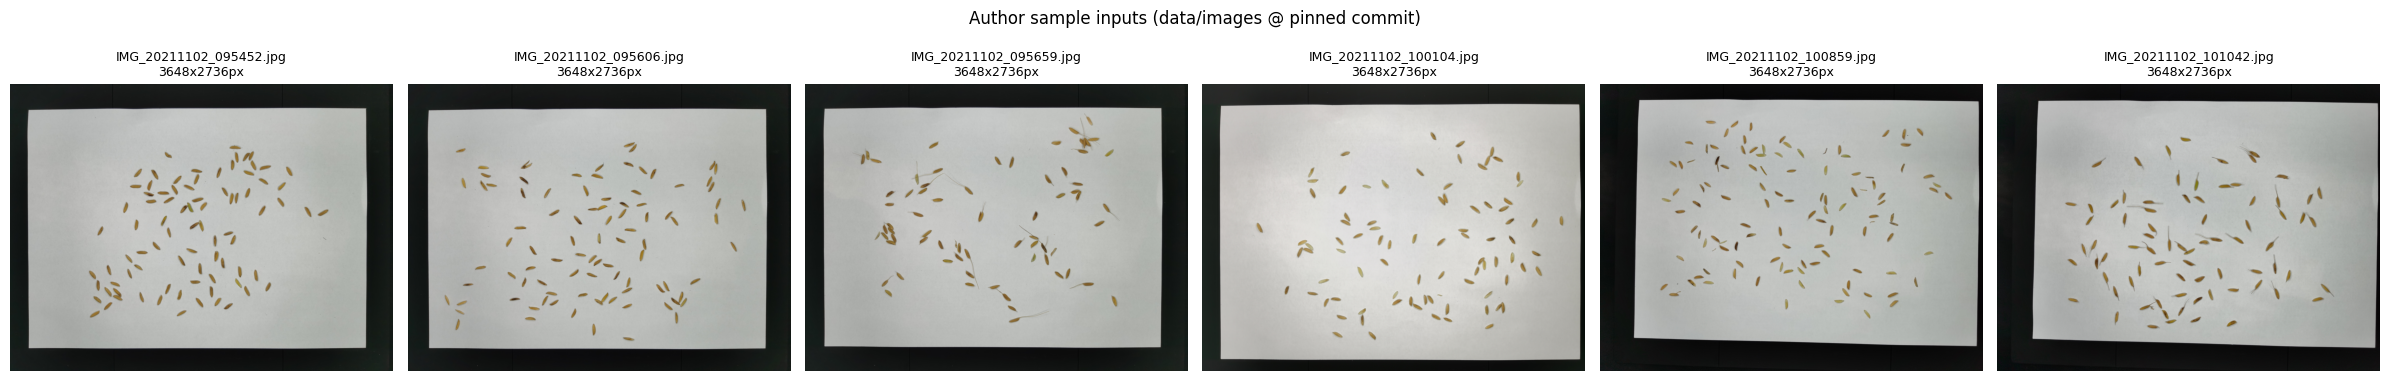

In [ ]:
import cv2, matplotlib.pyplot as plt

files = sorted((REPO_DIR / 'data/images').glob('*.jpg'))
print(len(files), 'sample photos')
fig, axes = plt.subplots(1, len(files), figsize=(4 * len(files), 4.2))
for ax, f in zip(axes, files):
    im = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)
    H, W, _ = im.shape
    ax.imshow(im); ax.set_title(f.name + f'\n{W}x{H}px', fontsize=9); ax.axis('off')
fig.suptitle('Author sample inputs (data/images @ pinned commit)', fontsize=12)
plt.tight_layout(); plt.show()


## 6. Compatibility wrapper (declared AI-generated adapter)

The 2022 checkpoint is a **full pickled PyTorch model**. On torch ≥ 2.6 the default `torch.load(weights_only=True)` refuses such pickles. We do **not** modify the author's code; instead a 10-line wrapper restores the legacy loader behaviour and then executes the unmodified `detect_rotation.py` via `runpy`. This is the only adaptation; everything else is author code.

**互換ラッパー:** torch 2.6 以降の `weights_only` 既定値変更のため、`torch.load` を旧動作に戻してから**無修正の** `detect_rotation.py` を実行します（唯一の適応箇所）。

In [ ]:
WRAPPER = REPO_DIR / 'run_detect_wrapper.py'
WRAPPER.write_text('''# Minimal compatibility wrapper (AI-generated, documented in the notebook).
# Restores legacy torch.load behaviour for the 2022 pickled checkpoint, then
# executes the UNMODIFIED author script detect_rotation.py.
import runpy, torch
_orig_load = torch.load
def _legacy_load(*args, **kwargs):
    kwargs.setdefault('weights_only', False)
    return _orig_load(*args, **kwargs)
torch.load = _legacy_load
runpy.run_path('detect_rotation.py', run_name='__main__')
''')
print(WRAPPER.read_text())


# Minimal compatibility wrapper (AI-generated, documented in the notebook).
# Restores legacy torch.load behaviour for the 2022 pickled checkpoint, then
# executes the UNMODIFIED author script detect_rotation.py.
import runpy, torch
_orig_load = torch.load
def _legacy_load(*args, **kwargs):
    kwargs.setdefault('weights_only', False)
    return _orig_load(*args, **kwargs)
torch.load = _legacy_load
runpy.run_path('detect_rotation.py', run_name='__main__')



## 7. Run the author's detection script (YOLO-rot inference)

Command and parameters are the repository README's detect command, verbatim: `--source ./data/images --img-size 640 --weights runs/train/exp1/weights/best.pt --conf 0.9` (defaults: IoU 0.45, 200 px tile overlap). Internally (`detect_rotation.py`): 640×640 tiles over the full-resolution photo → per-tile rotated-box NMS (`non_max_suppression_rotation`) → global rotated NMS (`detectron2 nms_rotated`) → per-seed `w=max(w,h)`, `h=min(w,h)` → calibration by `count_pixel` (paper sheet) → annotated overlays + Excel tables. Expected: `image 1/6 ... saved!` lines and `Results saved to ...` at the end (~1–3 min on GPU, several minutes on CPU).

**推論実行:** README の detect コマンドどおり（img-size 640, conf 0.9）。640pxタイル推論→回転NMS→用紙校正→注釈付き画像とExcel表が出力されます。

In [ ]:
import subprocess, sys

cmd = [sys.executable, 'run_detect_wrapper.py',
       '--source', './data/images', '--img-size', '640',
       '--weights', 'runs/train/exp1/weights/best.pt', '--conf', '0.9',
       '--device', DEVICE, '--save-dir', '/content/seed_results']
print(' '.join(cmd))
r = subprocess.run(cmd, cwd=str(REPO_DIR), timeout=3600)  # streams the author's own output
if r.returncode != 0:
    raise RuntimeError(f'detect_rotation.py exited with {r.returncode}')


/usr/bin/python3 run_detect_wrapper.py --source ./data/images --img-size 640 --weights runs/train/exp1/weights/best.pt --conf 0.9 --device 0 --save-dir /content/seed_results


## 8. Per-photo results (seed count, mean length/width in mm)

Read the author's main result workbook `meng_result.xls` written by `detect_rotation.py`. Columns: sample name, mean seed width (long axis, mm), mean seed height (short axis, mm), and seed count. If `count_pixel` found no paper sheet the means would be 0 — we surface that explicitly. A CSV export is written next to the notebook outputs in `/content`.

**写真ごとの結果:** 著者スクリプトが出力した `meng_result.xls`（平均長さ・平均幅 mm と粒数）を読み込み表示します。

In [ ]:
import pandas as pd
from pathlib import Path

result_root = sorted(Path('/content/seed_results').glob('exp*'))[-1]
print('author output dir:', result_root)
df = pd.read_excel(result_root / 'meng_result.xls', engine='xlrd')
df = df.set_index('name_index')  # the xls also carries an author row-counter column
display(df)
assert (df['rice_numbers'] > 0).all(), 'an image produced 0 detections'
assert (df[['w_means-(mm)', 'h_means-(mm)']] > 0).all().all(), 'calibration failed (0 mm): no paper sheet detected'
df.to_csv('/content/seed_measurements_summary.csv', index=False)
print('CSV export: /content/seed_measurements_summary.csv')


author output dir: /content/seed_results/exp


,Unnamed: 0,w_means-(mm),h_means-(mm),rice_numbers
name_index,,,,
IMG_20211102_095452,1,9.0511,2.4226,82
IMG_20211102_095606,2,9.1548,2.2256,86
IMG_20211102_095659,3,8.6967,2.4665,52
IMG_20211102_100104,4,8.1020,2.3177,81
IMG_20211102_100859,5,8.2364,2.2048,88
IMG_20211102_101042,6,9.2259,2.2804,73


CSV export: /content/seed_measurements_summary.csv


## 9. Per-seed measurements for one sample

The author's script also writes one Excel table per photo with every seed's long-axis length `w-(mm)` and short-axis width `h-(mm)`. We inspect the first sample photo (`IMG_20211102_095452.jpg`, deterministic choice: alphabetically first) and report simple summary statistics.

**1粒ごとの結果:** 最初のサンプル写真 `IMG_20211102_095452.jpg` の全粒の長さ・幅（mm）を表と要約統計で確認します。

In [ ]:
import numpy as np

SAMPLE = 'IMG_20211102_095452'
per = pd.read_excel(result_root / 'excel_files' / f'{SAMPLE}.xls', engine='xlrd')
per = per.set_index(per.columns[0])
per.columns = ['w-(mm)', 'h-(mm)']
display(per.head(15))
print('...')
print(f'seeds detected in {SAMPLE}: {len(per)}')
print(per.describe().round(2))
per.to_csv(f'/content/seed_measurements_{SAMPLE}.csv')


,w-(mm),h-(mm)
index,,
1,9.068,2.232
2,9.146,2.637
3,9.819,2.630
4,8.556,2.552
5,9.608,2.208
6,9.474,2.302
7,9.240,2.125
8,8.600,2.634
9,9.474,2.330


...
seeds detected in IMG_20211102_095452: 82
       w-(mm)  h-(mm)
count   82.00   82.00
mean     9.05    2.42
std      0.48    0.17
min      7.98    2.04
25%      8.63    2.31
50%      9.12    2.45
75%      9.50    2.54
max      9.95    2.82


## 10. Input vs. YOLO-rot prediction overlay

Side-by-side view of the original photo and the author's own annotated output (`draw_one_box` rotated boxes with per-seed index), straight from the script's output directory. **Reference annotations:** none exist for these demo photos (the training set is not public), so these overlays are **model predictions** on the author's sample.

**入力と予測の重ね合わせ:** 左が入力写真、右が著者スクリプト自身が出力した回転枠（予測）付き画像です。

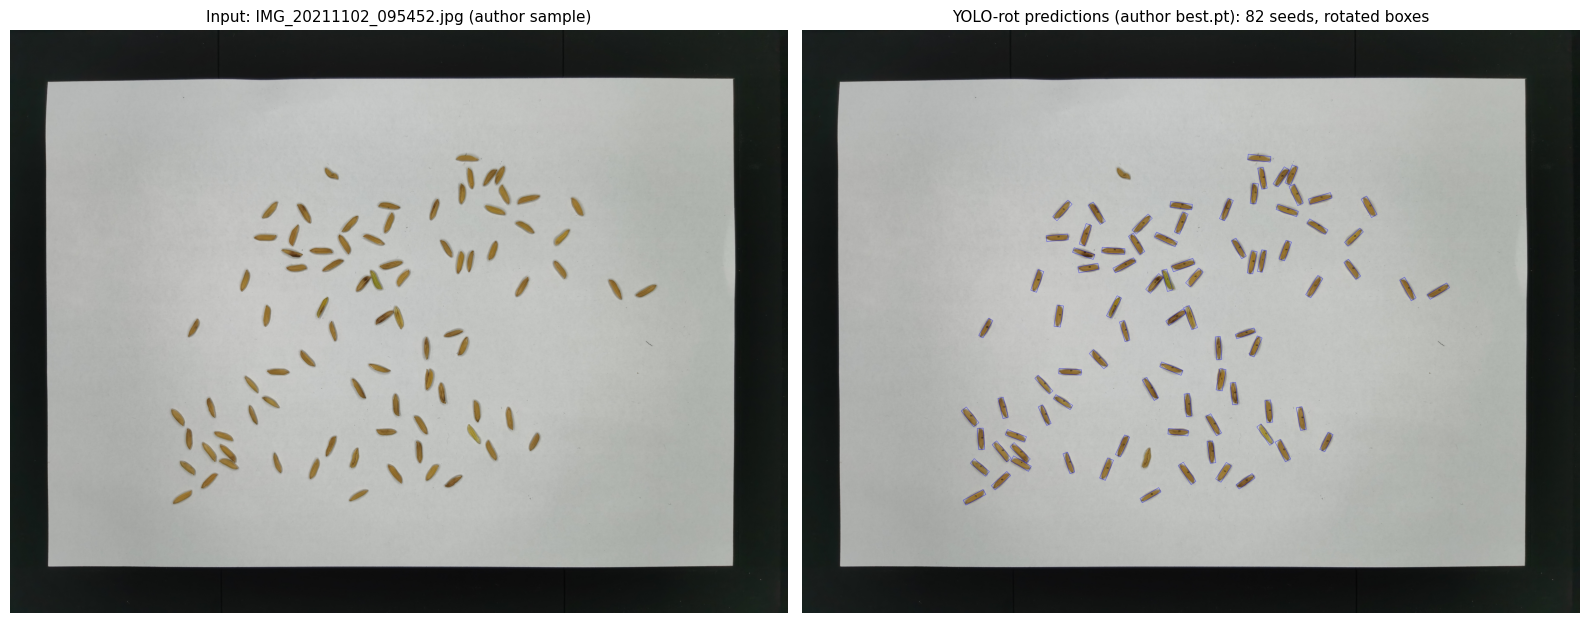

In [ ]:
import cv2, matplotlib.pyplot as plt

inp = cv2.cvtColor(cv2.imread(str(REPO_DIR / f'data/images/{SAMPLE}.jpg')), cv2.COLOR_BGR2RGB)
out = cv2.cvtColor(cv2.imread(str(result_root / 'images' / f'{SAMPLE}.jpg')), cv2.COLOR_BGR2RGB)
n_seeds = int(df.loc[SAMPLE, 'rice_numbers'])

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(inp); axes[0].set_title(f'Input: {SAMPLE}.jpg (author sample)', fontsize=11); axes[0].axis('off')
axes[1].imshow(out)
axes[1].set_title(f'YOLO-rot predictions (author best.pt): {n_seeds} seeds, rotated boxes', fontsize=11)
axes[1].axis('off')
plt.tight_layout(); plt.show()


## 11. Per-seed size distribution (additional notebook-generated graph)

A histogram of the per-seed long/short axes from the table above. This graph is **created by this notebook** from the actual measurements; it is not a figure from the paper.

**付加グラフ:** 上の1粒ごとの測定値から本ノートブックが描いたヒストグラム（論文の図ではありません）。

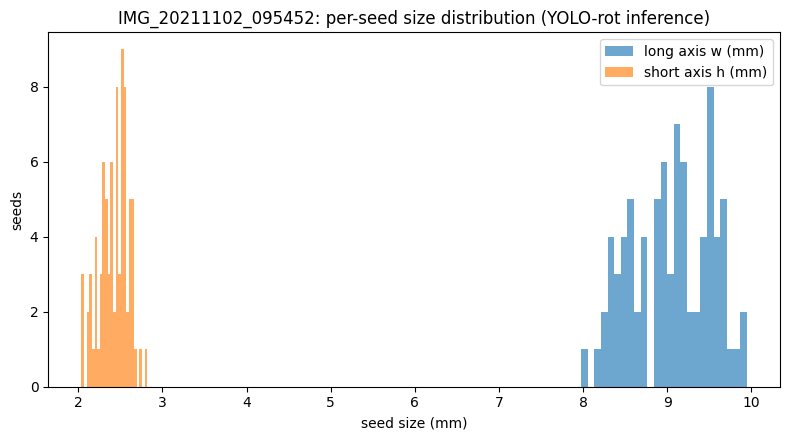

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5))
plt.hist(per['w-(mm)'], bins=25, alpha=0.65, label='long axis w (mm)')
plt.hist(per['h-(mm)'], bins=25, alpha=0.65, label='short axis h (mm)')
plt.xlabel('seed size (mm)'); plt.ylabel('seeds')
plt.title(f'{SAMPLE}: per-seed size distribution (YOLO-rot inference)')
plt.legend(); plt.tight_layout(); plt.show()


## 12. Interpretation, validation record and references

**What was executed (validated on Colab, CPU and T4 GPU):** the authors' unmodified `detect_rotation.py` @ commit `43bbc77` with their released `best.pt` on the six author sample photos; seed counts and per-seed mm measurements were produced and verified against the pinned git blob SHAs. Runtimes measured during validation are printed in the executed outputs above.

**How mm calibration works here:** `utils/eage.py: count_pixel` finds the largest quadrilateral in the photo (the paper sheet), computes `pixel = (210+279)*2 / perimeter_sum` [mm per pixel] — the constant is the author's own code (`eage.py:90`). If no sheet is found, the script's means would be 0; the results cell guards against that. Note the author's constant corresponds to a 210 × 279 mm sheet, not A4's 297 mm — preserved as-is for fidelity.

**Known deviations / notes:**
- The only code change is the `torch.load(weights_only=False)` wrapper (cell 6); author files are untouched.
- The author pipeline passes rotation angles in **degrees** to `detectron2`'s `nms_rotated` (which documents radians); this only affects rotated-NMS deduplication quality and is preserved exactly as released.
- Tile windows are `range(0, dim-640, 440)`, so a thin margin at the photo edges is not covered by any tile — again the author's own behavior.
- Full paper text was unavailable (ScienceDirect block, no OA copy), so method context rests on the abstract record and — for everything executed — on the authors' code itself.

**Scope reminder:** this single-example inference does not verify the paper's dataset-level accuracy or comparison results.

**参照 / References**
- Paper: *Computers and Electronics in Agriculture* 205 (2023) 107583, DOI 10.1016/j.compag.2022.107583.
- Code: https://github.com/IceAndSea/Seed-size-detection @ `43bbc7752ccb38c6fb2a224804601b83ada5b81a` (no LICENSE file in the repository — reuse terms unclear; used here with attribution for research reproduction).
- Weights: `runs/train/exp1/weights/best.pt` (14,799,399 bytes, git blob `e39a5e18`).
- Online tool: [SeedRuler](http://www.xhhuanglab.cn/tool/SeedRuler.html).
- Follow-up: YOLOrot2.0, *Advanced Agro-Engineering* (2024) 100599; dataset rice370 (Kaggle, `cccccabbage/rice370`).

**検証の記録（日本語）:** Colab の CPU と T4 GPU の両方で、新規ランタイムで先頭から全セルを実行して検証しました。著者コードは無修正（ラッパー1つのみ）。単一サンプルでの推論であり、論文のデータセット精度の検証ではありません。